In [ ]:
import keras
from keras import layers, ops
import tensorflow as tf

LATENT_DIM = 128

class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = ops.shape(z_mean)[0]
        dim = ops.shape(z_mean)[1]
        epsilon = keras.random.normal(shape=(batch, dim), mean=0.0, stddev=1.0)
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon

#Encoder
enc_in = layers.Input(shape=(64, 64, 3), name="encoder_input")

x = layers.Conv2D(64, kernel_size=4, strides=2, padding="same", use_bias=False)(enc_in)
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(0.2)(x)

x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(0.2)(x)

x = layers.Conv2D(256, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(0.2)(x)

x = layers.Flatten()(x)
x = layers.Dense(512, activation="relu")(x)

z_mean = layers.Dense(LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

encoder = keras.Model(enc_in, [z_mean, z_log_var, z], name="encoder")

#Decoder
dec_in = layers.Input(shape=(LATENT_DIM,), name="decoder_input")

x = layers.Dense(8 * 8 * 256, use_bias=False)(dec_in)
x = layers.Reshape((8, 8, 256))(x)
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(0.2)(x)

x = layers.Conv2DTranspose(128, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(0.2)(x)

x = layers.Conv2DTranspose(64, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.GroupNormalization(groups=8)(x)
x = layers.LeakyReLU(0.2)(x)

dec_out = layers.Conv2DTranspose(3, kernel_size=4, strides=2, padding="same", activation="sigmoid")(x)

decoder = keras.Model(dec_in, dec_out, name="decoder")

#VAE
class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=0.001, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta

        self.total_loss_tracker = keras.metrics.Mean(name="loss")
        self.rec_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.rec_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs, training=False):
        z_mean, z_log_var, z = self.encoder(inputs, training=training)
        latent = z if training else z_mean
        return self.decoder(latent, training=training)

    @tf.function
    def train_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(x, training=True)
            reconstruction = self.decoder(z, training=True)

            x_tf = tf.convert_to_tensor(x)
            rec_tf = tf.convert_to_tensor(reconstruction)

            l1_loss = tf.reduce_mean(tf.abs(x_tf - rec_tf), axis=(1, 2, 3))
            ssim_val = tf.image.ssim(x_tf, rec_tf, max_val=1.0)
            ssim_loss = tf.reduce_mean(1.0 - ssim_val)
            rec_loss = (0.8 * ssim_loss + 0.2 * tf.reduce_mean(l1_loss)) * 1000.0

            kl_loss = -0.5 * tf.reduce_sum(1.0 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1)
            kl_loss = tf.reduce_mean(kl_loss)

            total_loss = rec_loss + (self.beta * kl_loss)

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.rec_loss_tracker.update_state(rec_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.rec_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    @tf.function
    def test_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data

        z_mean, z_log_var, z = self.encoder(x, training=False)
        reconstruction = self.decoder(z, training=False)

        x_tf = tf.convert_to_tensor(x)
        rec_tf = tf.convert_to_tensor(reconstruction)

        l1_loss = tf.reduce_mean(tf.abs(x_tf - rec_tf), axis=(1, 2, 3))
        ssim_val = tf.image.ssim(x_tf, rec_tf, max_val=1.0)
        ssim_loss = tf.reduce_mean(1.0 - ssim_val)
        rec_loss = (0.8 * ssim_loss + 0.2 * tf.reduce_mean(l1_loss)) * 1000.0

        kl_loss = -0.5 * tf.reduce_sum(1.0 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1)
        kl_loss = tf.reduce_mean(kl_loss)

        total_loss = rec_loss + (self.beta * kl_loss)

        self.total_loss_tracker.update_state(total_loss)
        self.rec_loss_tracker.update_state(rec_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.rec_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

In [ ]:
vae = VAE(encoder, decoder, beta=0.001)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=2e-4))

In [ ]:
import os

TOKEN = "KGAT_ff3eccd3fd9aecceb14dafea44e3ef2f"

os.environ["KAGGLE_API_TOKEN"] = TOKEN

kaggle_dir = os.path.expanduser("~/.kaggle")
os.makedirs(kaggle_dir, exist_ok=True)
token_path = os.path.join(kaggle_dir, "access_token")

with open(token_path, "w") as f:
    f.write(TOKEN.strip())

os.chmod(token_path, 0o600)

!kaggle competitions download -c mg-practica-1-generando-caras
!unzip -o -q mg-practica-1-generando-caras.zip -d dataset_competencia
!ls -lh dataset_competencia

100% 186M/186M [00:01<00:00, 162MB/s]

total 8.0K
drwxr-xr-x 4 root root 4.0K Oct 24 20:04 CelebAMask
-rw-r--r-- 1 root root 3.3K Sep  8 09:49 Create_Submission.ipynb


In [ ]:
import tensorflow as tf

RUTA_FOTOS = "dataset_competencia/CelebAMask/images"

x_train = tf.keras.utils.image_dataset_from_directory(
    RUTA_FOTOS,
    labels=None,
    image_size=(64, 64),
    batch_size=128,
    validation_split=0.15,
    subset="training",
    seed=42,
    shuffle=True
)

x_test = tf.keras.utils.image_dataset_from_directory(
    RUTA_FOTOS,
    labels=None,
    image_size=(64, 64),
    batch_size=128,
    validation_split=0.15,
    subset="validation",
    seed=42,
    shuffle=False
)

x_train = x_train.map(lambda x: (x / 255.0, x / 255.0)).prefetch(tf.data.AUTOTUNE)
x_test = x_test.map(lambda x: (x / 255.0, x / 255.0)).prefetch(tf.data.AUTOTUNE)

Found 30000 files.
Using 25500 files for training.
Found 30000 files.
Using 4500 files for validation.


In [ ]:
vae_logs = vae.fit(
    x_train,
    epochs=50,
    validation_data=x_test,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
    ]
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 44s 139ms/step - kl_loss: 834.8301 - loss: 463.4896 - reconstruction_loss: 462.6546 - val_kl_loss: 834.6752 - val_loss: 351.7368 - val_reconstruction_loss: 350.9021 - learning_rate: 2.0000e-04
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 63ms/step - kl_loss: 852.4390 - loss: 313.0866 - reconstruction_loss: 312.2341 - val_kl_loss: 823.5891 - val_loss: 288.0851 - val_reconstruction_loss: 287.2616 - learning_rate: 2.0000e-04
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 65ms/step - kl_loss: 836.5371 - loss: 275.0644 - reconstruction_loss: 274.2277 - val_kl_loss: 842.9556 - val_loss: 263.5043 - val_reconstruction_loss: 262.6613 - learning_rate: 2.0000e-04
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - kl_loss: 837.9875 - loss: 254.6743 - reconstruction_loss: 253.8362 - val_kl_loss: 837.3019 - val_loss: 248.4016 - val_reconstruction_loss: 247.5644 - learning_rate: 2.0000e-04
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - kl_loss: 837.03

In [ ]:
vae_logs.history.keys()

dict_keys(['kl_loss', 'loss', 'reconstruction_loss', 'val_kl_loss', 'val_loss', 'val_reconstruction_loss', 'learning_rate'])

In [ ]:
import matplotlib.pyplot as plt

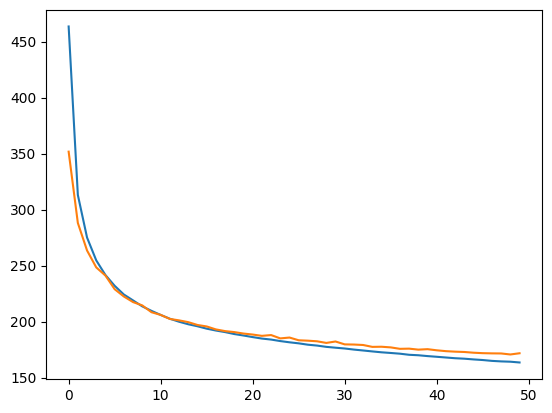

In [ ]:
plt.plot(vae_logs.history['loss'])
plt.plot(vae_logs.history['val_loss'])

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step


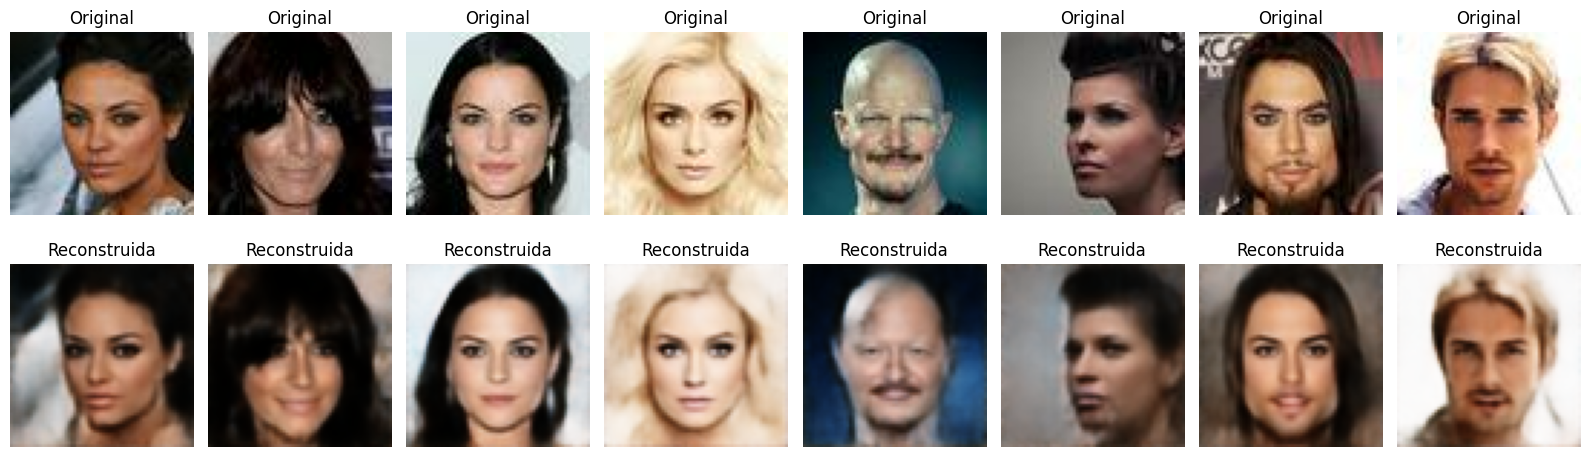

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

images_batch, _ = next(iter(x_test))
original_imgs = images_batch.numpy()

z_mean, _, _ = vae.encoder.predict(images_batch)
decoded_imgs = vae.decoder.predict(z_mean)

n_images = 8
plt.figure(figsize=(16, 5))
for i in range(n_images):
    ax = plt.subplot(2, n_images, i + 1)
    plt.imshow(original_imgs[i])
    plt.title("Original")
    ax.axis("off")

    ax = plt.subplot(2, n_images, i + 1 + n_images)
    plt.imshow(decoded_imgs[i])
    plt.title("Reconstruida")
    ax.axis("off")

plt.tight_layout()
plt.show()

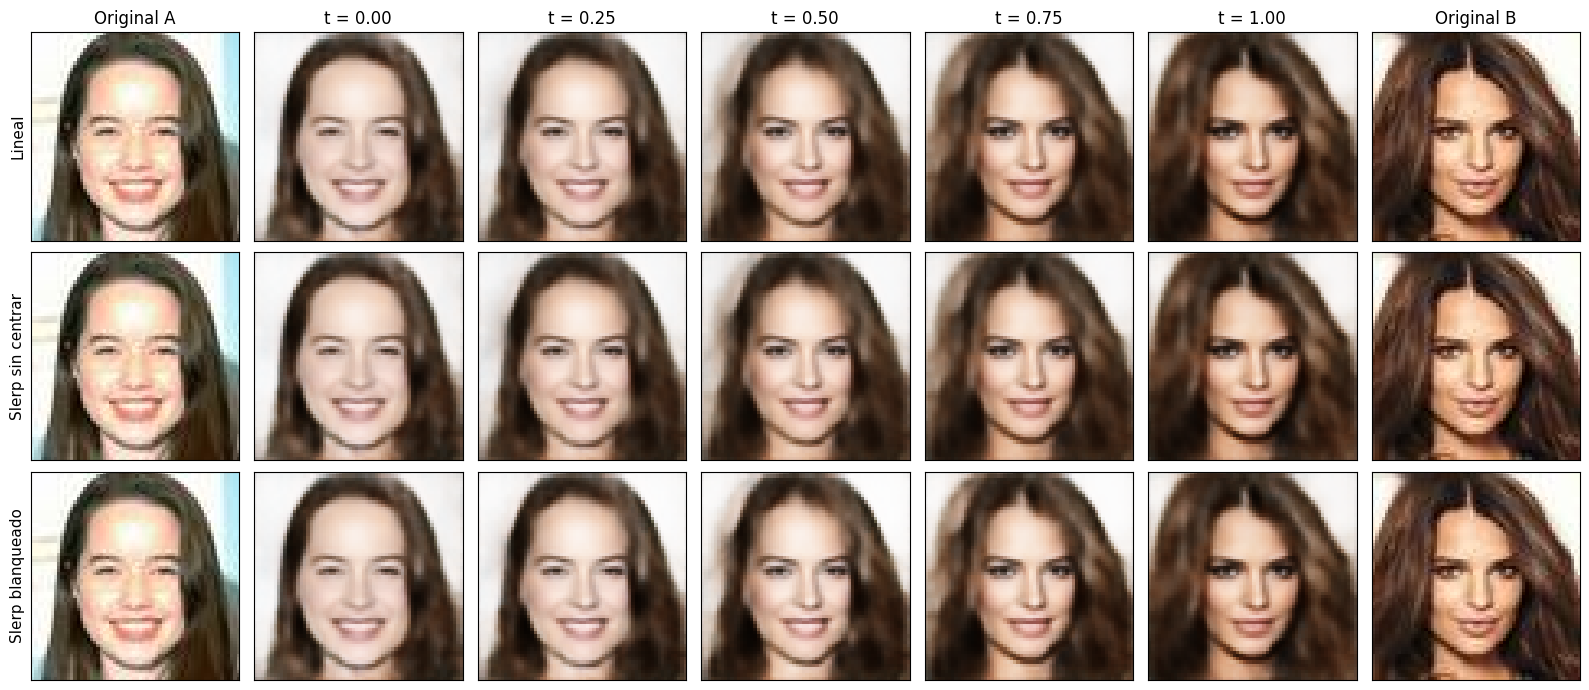

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Caras a mezclar (para el requisito del enunciado, sustituir por fotos que NO estén en el dataset)
img_A = images_batch[10]
img_B = images_batch[20]
z_mean_AB, _, _ = vae.encoder.predict(np.array([img_A, img_B]), verbose=0)
z_A, z_B = z_mean_AB

# --- Estadísticos del espacio latente de caras reales ---
z_ref = vae.encoder.predict(x_test, verbose=0)[0]
mu = z_ref.mean(axis=0)
w, V = np.linalg.eigh(np.cov(z_ref, rowvar=False))
w = np.clip(w, 1e-6, None)
W = V @ np.diag(1.0 / np.sqrt(w)) @ V.T          # blanqueo: la distribución pasa a ser ~N(0, I)
W_inv = V @ np.diag(np.sqrt(w)) @ V.T
blanquear = lambda z: (z - mu) @ W
desblanquear = lambda u: u @ W_inv + mu

def slerp(t, a, b):
    """Dirección por interpolación esférica; módulo por interpolación lineal (vale con normas distintas)."""
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    ua, ub = a / na, b / nb
    omega = np.arccos(np.clip(np.dot(ua, ub), -1.0, 1.0))
    if np.sin(omega) < 1e-6:
        d = (1 - t) * ua + t * ub
    else:
        d = (np.sin((1 - t) * omega) * ua + np.sin(t * omega) * ub) / np.sin(omega)
    return d * ((1 - t) * na + t * nb)

metodos = {
    "Lineal": lambda t: (1 - t) * z_A + t * z_B,
    "Slerp sin centrar": lambda t: slerp(t, z_A, z_B),
    "Slerp blanqueado": lambda t: desblanquear(slerp(t, blanquear(z_A), blanquear(z_B))),
}
ts = [0.0, 0.25, 0.5, 0.75, 1.0]

zs = np.array([f(t) for f in metodos.values() for t in ts], dtype="float32")
caras = np.clip(vae.decoder.predict(zs, verbose=0), 0.0, 1.0)

fig, axs = plt.subplots(len(metodos), len(ts) + 2, figsize=(16, 7))
for r, nombre in enumerate(metodos):
    axs[r, 0].imshow(np.clip(img_A, 0, 1)); axs[r, 0].set_title("Original A" if r == 0 else "")
    axs[r, -1].imshow(np.clip(img_B, 0, 1)); axs[r, -1].set_title("Original B" if r == 0 else "")
    for j, t in enumerate(ts):
        axs[r, j + 1].imshow(caras[r * len(ts) + j])
        if r == 0:
            axs[r, j + 1].set_title(f"t = {t:.2f}")
    axs[r, 0].set_ylabel(nombre, fontsize=11)
for ax in axs.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [34]:
REF_N = 3000     # caras reales de train que usamos como referencia
N_FID = 200     # caras generadas para el FID estable

# InceptionV3 de ImageNet sin la capa final: devuelve un vector de 2048 por imagen
inception = keras.applications.InceptionV3(include_top=False, pooling="avg", weights="imagenet",
                                           input_shape=(299, 299, 3))


def rasgos(imgs, batch=16):
    """imgs (N, 64, 64, 3) en [0, 1]. Igual que el evaluador: gris de 8 bits -> 3 canales -> 299x299."""
    g = np.round(imgs @ np.array([0.299, 0.587, 0.114]) * 255).clip(0, 255) / 255.0
    out = []
    for i in range(0, len(g), batch):
        b = np.repeat(g[i:i + batch, ..., None], 3, axis=-1).astype("float32")
        b = tf.image.resize(b, (299, 299), method="bilinear")
        out.append(inception.predict(keras.applications.inception_v3.preprocess_input(b * 255.0), verbose=0))
    return np.concatenate(out)


def estadisticos(f):
    return f.mean(axis=0), np.cov(f, rowvar=False)


def fid_entre(mu1, s1, mu2, s2):
    """FID = |mu1 - mu2|^2 + Tr(S1 + S2 - 2 (S1 S2)^(1/2)). La traza de la raíz sale de los autovalores de S1 S2."""
    eig = np.linalg.eigvals(s1 @ s2)
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(s1) + np.trace(s2) - 2 * np.sqrt(np.clip(eig.real, 0, None)).sum())

# Extraemos exactamente REF_N imágenes reales del dataset x_train usando .take()
imgs_list = []
count = 0
for x_batch, _ in x_train:
    imgs_list.append(x_batch)
    count += x_batch.shape[0]
    if count >= REF_N:
        break

x_train_ref = np.concatenate(imgs_list, axis=0)[:REF_N]

mu_ref, sig_ref = estadisticos(rasgos(x_train_ref))      # estadísticos de las caras reales


def fid_local(imgs):
    mu_i, sig_i = estadisticos(rasgos(imgs))
    return fid_entre(mu_i, sig_i, mu_ref, sig_ref)

In [35]:
from sklearn.mixture import GaussianMixture

# ------------------------------------------------------------------------------
# Elegir cómo muestrear el espacio latente.
# 1) Se ajusta una mezcla de K gaussianas sobre los latentes de las caras reales
#    (K=1 es tu método anterior: una sola gaussiana con media y covarianza empírica).
# 2) La temperatura T acerca cada muestra al centro de su gaussiana (T=1 no cambia nada).
# 3) Se prueban varias combinaciones (K, T): para cada una se generan N_TUNE caras
#    y se calcula UN FID del grupo. Las caras se descartan; solo se compara el número.
# ------------------------------------------------------------------------------
z_all = np.concatenate([
    vae.encoder.predict(x_train, verbose=0)[0],
    vae.encoder.predict(x_test, verbose=0)[0],
])
print("Latentes:", z_all.shape)

def muestrear(gmm, n, T=1.0):
    z, comp = gmm.sample(n)
    centros = gmm.means_[comp]
    z = centros + T * (z - centros)
    imgs = vae.decoder.predict(z.astype("float32"), batch_size=128, verbose=0)
    return np.clip(imgs, 0.0, 1.0)

N_TUNE = 1000          # con 200 muestras el FID es muy ruidoso; para comparar configuraciones usamos 1000
gmms, resultados = {}, {}
for K in (1, 8, 24):
    gmms[K] = GaussianMixture(K, covariance_type="full", reg_covar=1e-4, random_state=0).fit(z_all)
    for T in (0.7, 0.8, 0.9, 1.0):
        resultados[(K, T)] = fid_local(muestrear(gmms[K], N_TUNE, T))
        print(f"K={K:>2}  T={T:.1f}  ->  FID({N_TUNE}) = {resultados[(K, T)]:.2f}")

best_K, best_T = min(resultados, key=resultados.get)
print(f"\n>>> Mejor configuración: K={best_K}, T={best_T}  (FID {resultados[(best_K, best_T)]:.2f}) <<<")

Latentes: (30000, 128)
K= 1  T=0.7  ->  FID(1000) = 90.30
K= 1  T=0.8  ->  FID(1000) = 88.37
K= 1  T=0.9  ->  FID(1000) = 87.89
K= 1  T=1.0  ->  FID(1000) = 88.69
K= 8  T=0.7  ->  FID(1000) = 77.43
K= 8  T=0.8  ->  FID(1000) = 76.14
K= 8  T=0.9  ->  FID(1000) = 76.06
K= 8  T=1.0  ->  FID(1000) = 76.53
K=24  T=0.7  ->  FID(1000) = 76.52
K=24  T=0.8  ->  FID(1000) = 75.87
K=24  T=0.9  ->  FID(1000) = 75.96
K=24  T=1.0  ->  FID(1000) = 76.76

>>> Mejor configuración: K=24, T=0.8  (FID 75.87) <<<


In [36]:
import os
from PIL import Image

n_images = 200
out_folder = "random_imgs"
os.makedirs(out_folder, exist_ok=True)

# 200 caras NUEVAS con la configuración ganadora (sin filtrar ni ordenar)
generated_imgs_rgb = muestrear(gmms[best_K], n_images, best_T)
imgs_uint8 = np.round(generated_imgs_rgb * 255.0).clip(0, 255).astype(np.uint8)

# Se guardan en RGB, igual que Create_Submission.ipynb. La conversión a gris la hace
# la celda del CSV con cv2.IMREAD_GRAYSCALE, es decir, EXACTAMENTE como la evalúa Kaggle.
for i in range(n_images):
    Image.fromarray(imgs_uint8[i], "RGB").save(f"{out_folder}/img_{i+1:03d}.png")

print(f"Se han generado y guardado {n_images} imágenes en '{out_folder}/'.")

/tmp/ipykernel_2069/616357929.py:15: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(imgs_uint8[i], "RGB").save(f"{out_folder}/img_{i+1:03d}.png")


Se han generado y guardado 200 imágenes en 'random_imgs/'.


In [37]:
import glob, cv2, numpy as np, pandas as pd

# Misma lectura a gris que Create_Submission.ipynb (cv2.IMREAD_GRAYSCALE)
out_folder = "random_imgs"
imgs_arr = []
for img_path in sorted(glob.glob(out_folder + "/*.png")):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (64, 64), interpolation=cv2.INTER_AREA)
    imgs_arr.append(img.flatten())
df = pd.DataFrame(np.array(imgs_arr))

# Formato de entrega de Kaggle: ID + 4096 píxeles (SIN columna Usage, Kaggle la rechaza)
df.insert(0, "ID", range(1, len(df) + 1))
df.to_csv("submission.csv", index=False)

print(df.shape, "(esperado: (200, 4097))")

(200, 4097) (esperado: (200, 4097))


In [38]:
# FID con 200 muestras (el tamaño real de la entrega), promediado en 5 sorteos:
# método anterior (K=1, T=1) frente a la configuración elegida.
def fid_200(K, T, reps=5):
    return np.mean([fid_local(muestrear(gmms[K], 200, T)) for _ in range(reps)])

print(f"Método anterior     (K=1,  T=1.0): {fid_200(1, 1.0):.2f}")
print(f"Configuración nueva (K={best_K}, T={best_T}): {fid_200(best_K, best_T):.2f}")
print(f"FID de las 200 imágenes guardadas: {fid_local(generated_imgs_rgb):.2f}")

Método anterior     (K=1,  T=1.0): 104.14
Configuración nueva (K=24, T=0.8): 90.84
FID de las 200 imágenes guardadas: 90.84
